# Rice image classification (Keras CNN)


## 1. Setup

In [ ]:
#!pip install -q kagglehub scikit-learn

In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

keras.utils.set_random_seed(SEED)

## 2. Download and find the data

In [ ]:
path = kagglehub.dataset_download("muratkokludataset/rice-image-dataset")
BASE_DIR = os.path.join(path, "Rice_Image_Dataset")
if not os.path.exists(BASE_DIR):
    BASE_DIR = path

class_names = sorted(d for d in os.listdir(BASE_DIR) if os.path.isdir(os.path.join(BASE_DIR, d)))
NUM_CLASSES = len(class_names)
print(class_names)

Using Colab cache for faster access to the 'rice-image-dataset' dataset.
['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']


## 3. Split the files first: 80% train / 10% validation / 10% test


In [ ]:
file_paths, labels = [], []
for idx, name in enumerate(class_names):
    folder = os.path.join(BASE_DIR, name)
    for f in os.listdir(folder):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            file_paths.append(os.path.join(folder, f))
            labels.append(idx)
file_paths, labels = np.array(file_paths), np.array(labels)

train_p, rest_p, train_y, rest_y = train_test_split(
    file_paths, labels, test_size=0.2, stratify=labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(
    rest_p, rest_y, test_size=0.5, stratify=rest_y, random_state=SEED)

print(len(train_p), len(val_p), len(test_p))

60000 7500 7500


## 4. tf.data pipelines

In [ ]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, tf.one_hot(label, NUM_CLASSES)

def make_ds(paths, ys, training):
    ds = tf.data.Dataset.from_tensor_slices((paths, ys))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_p, train_y, training=True)
val_ds   = make_ds(val_p,   val_y,   training=False)
test_ds  = make_ds(test_p,  test_y,  training=False)

# Raw pixels should be 0-255 here; the model normalizes them itself.
x, y = next(iter(train_ds))
print("input range:", x.numpy().min(), "-", x.numpy().max(), "| shape:", x.shape)

input range: 0.0 - 255.0 | shape: (32, 128, 128, 3)


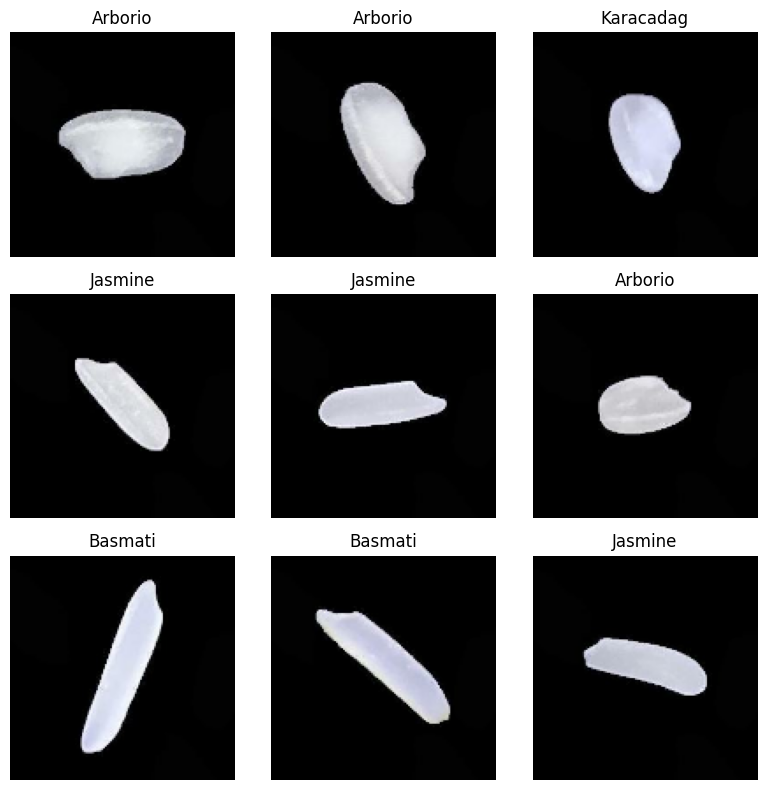

In [ ]:
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.title(class_names[int(np.argmax(y[i]))])
    plt.axis("off")
plt.tight_layout(); plt.show()

## 5. Models
`Rescaling(1/255)`

In [ ]:
def build_flatten_cnn():
    return keras.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPool2D(2),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPool2D(2),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPool2D(2),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="cnn_flatten")

def build_gap_cnn():
    return keras.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPool2D(2),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPool2D(2),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPool2D(2),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.5),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="cnn_gap")

def compile_model(m):
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return m

CNN  = compile_model(build_flatten_cnn())
CNN1 = compile_model(build_gap_cnn())
CNN.summary()
CNN1.summary()

Model: "cnn_flatten"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,325 (16.36 MB)

 Trainable params: 4,288,325 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Model: "cnn_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,165 (1.16 MB)

 Trainable params: 304,165 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Training (each model saves its own best checkpoint)

In [ ]:
def train(model, epochs=5):
    callbacks = [
        keras.callbacks.ModelCheckpoint(f"best_{model.name}.keras", save_best_only=True,
                                        monitor="val_loss", mode="min", verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    ]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks)

history_cnn  = train(CNN)
history_cnn1 = train(CNN1)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9144 - loss: 0.2508
Epoch 2: val_loss improved from 0.22611 to 0.12046, saving model to best_cnn_gap.keras

Epoch 2: finished saving model to best_cnn_gap.keras
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 90s 48ms/step - accuracy: 0.9290 - loss: 0.2135 - val_accuracy: 0.9643 - val_loss: 0.1205
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9574 - loss: 0.1336
Epoch 3: val_loss improved from 0.12046 to 0.07923, saving model to best_cnn_gap.keras

Epoch 3: finished saving model to best_cnn_gap.keras
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 90s 48ms/step - accuracy: 0.9654 - loss: 0.1116 - val_accuracy: 0.9771 - val_loss: 0.0792
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9737 - loss: 0.0863
Epoch 4: val_loss improved from 0.07923 to 0.02691, saving model to best_cnn_gap.keras

Epoch 4: finished saving model to best_cnn_gap.keras
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 90s 48ms/step - accuracy: 0.9749 - loss: 0.0818 - 

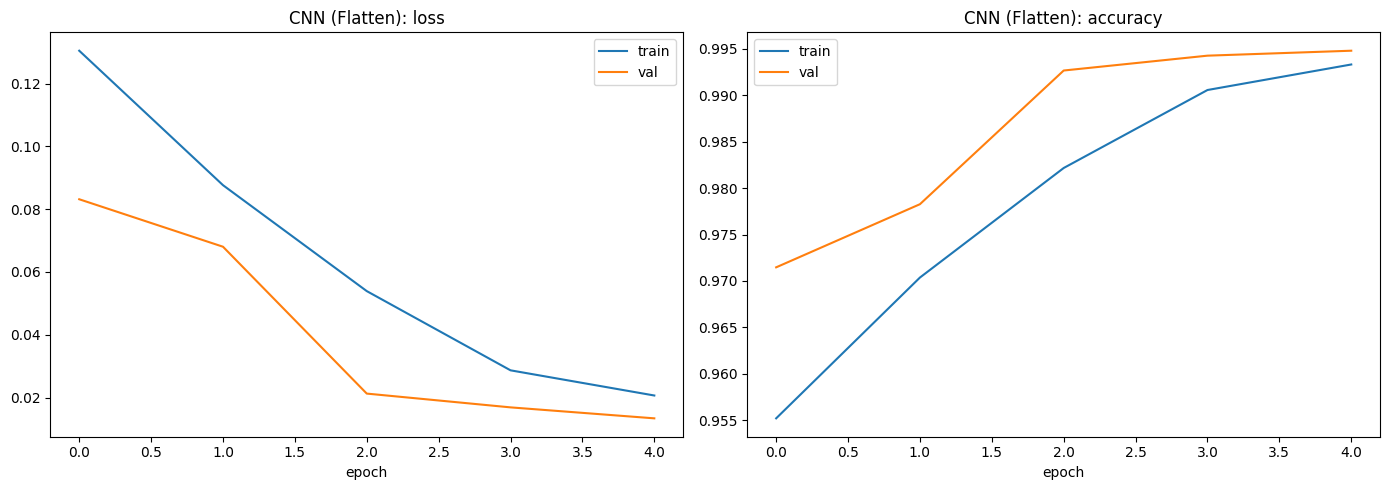

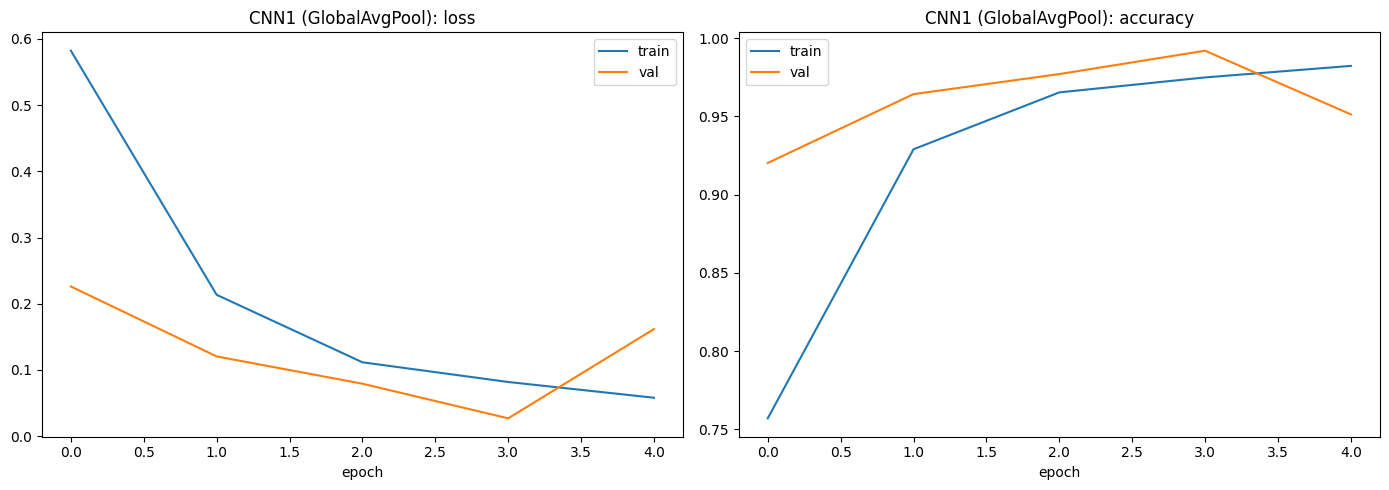

In [ ]:
def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(history.history["loss"], label="train")
    ax[0].plot(history.history["val_loss"], label="val")
    ax[0].set_title(f"{title}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(history.history["accuracy"], label="train")
    ax[1].plot(history.history["val_accuracy"], label="val")
    ax[1].set_title(f"{title}: accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history_cnn,  "CNN (Flatten)")
plot_history(history_cnn1, "CNN1 (GlobalAvgPool)")

## 7. Compare models on the held-out test set

In [ ]:
best_cnn  = keras.models.load_model("best_cnn_flatten.keras")
best_cnn1 = keras.models.load_model("best_cnn_gap.keras")

for name, m in [("CNN (Flatten)", best_cnn), ("CNN1 (GAP)", best_cnn1)]:
    loss, acc = m.evaluate(test_ds, verbose=0)
    print(f"{name:15s} test loss {loss:.4f} | test accuracy {acc:.4f}")

CNN (Flatten)   test loss 0.0145 | test accuracy 0.9961
CNN1 (GAP)      test loss 0.0257 | test accuracy 0.9923


#8 .final_model

              precision    recall  f1-score   support

     Arborio     0.9973    0.9947    0.9960      1500
     Basmati     0.9920    0.9973    0.9947      1500
      Ipsala     1.0000    1.0000    1.0000      1500
     Jasmine     0.9966    0.9900    0.9933      1500
   Karacadag     0.9947    0.9987    0.9967      1500

    accuracy                         0.9961      7500
   macro avg     0.9961    0.9961    0.9961      7500
weighted avg     0.9961    0.9961    0.9961      7500



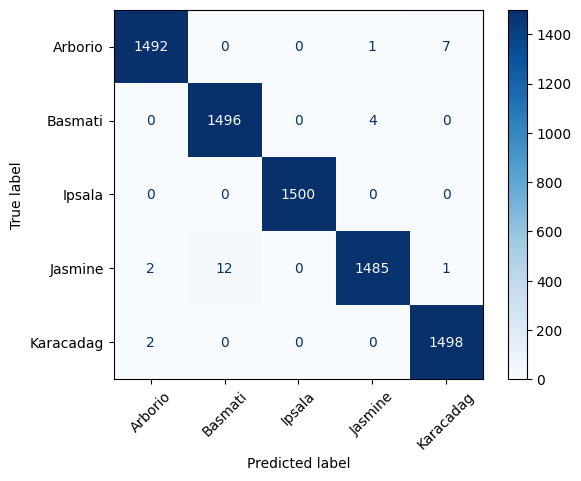

In [ ]:
final_model = best_cnn

probs = final_model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)
y_true = test_y                      # test_ds is not shuffled, so the order matches

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(
    xticks_rotation=45, cmap="Blues")
plt.show()

## 8. Predictions on real images

In [ ]:
def predict_image(img_path, model=final_model):
    img = keras.utils.load_img(img_path, target_size=IMG_SIZE)   # same size as training
    arr = keras.utils.img_to_array(img)[None, ...]                # raw 0-255, the model rescales it
    p = model.predict(arr, verbose=0)[0]
    return class_names[int(p.argmax())], float(p.max())

label, conf = predict_image(test_p[0])
print(f"true: {class_names[test_y[0]]} | predicted: {label} ({conf:.1%})")

true: Ipsala | predicted: Ipsala (100.0%)


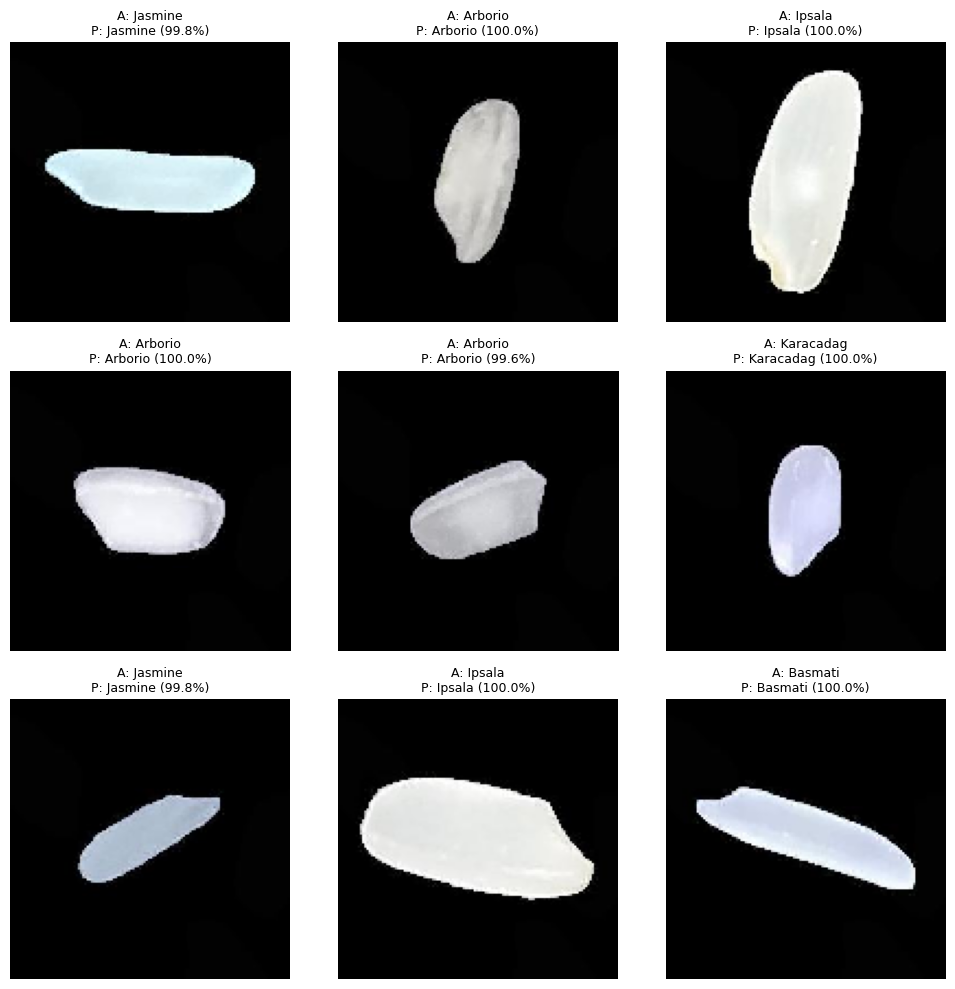

In [ ]:
# 9 random test images, predicted in one batch
idx = np.random.default_rng(SEED).choice(len(test_p), 9, replace=False)
batch = np.stack([keras.utils.img_to_array(keras.utils.load_img(test_p[i], target_size=IMG_SIZE)) for i in idx])
probs = final_model.predict(batch, verbose=0)

plt.figure(figsize=(10, 10))
for k, i in enumerate(idx):
    plt.subplot(3, 3, k + 1)
    plt.imshow(batch[k].astype("uint8"))
    p = probs[k]
    plt.title(f"A: {class_names[test_y[i]]}\nP: {class_names[p.argmax()]} ({p.max():.1%})", fontsize=9)
    plt.axis("off")
plt.tight_layout(); plt.show()